In [1]:
import os
!lscpu | grep "Model name\|CPU(s):"
!free -h

CPU(s):                                  4
Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz
NUMA node0 CPU(s):                       0-3
               total        used        free      shared  buff/cache   available
Mem:            31Gi       1.3Gi        25Gi       1.2Mi       4.7Gi        30Gi
Swap:             0B          0B          0B


In [2]:
import time
start_time = time.time()

In [3]:
import pandas as pd, torch
import matplotlib.pyplot as plt, textwrap
import numpy as np
from PIL import Image
from sentence_transformers import SentenceTransformer
from IPython.display import display, Image as IPyImage

# Uncomment if use online drive (collab)
#from google.colab import drive

In [4]:
img_model = SentenceTransformer("sentence-transformers/clip-ViT-B-32")
txt_model = SentenceTransformer("sentence-transformers/clip-ViT-B-32-multilingual-v1")

modules.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/1.91k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.03k [00:00<?, ?B/s]

0_CLIPModel/model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

0_CLIPModel/model.safetensors: downloading bytes:           |  0.00B            

... (18 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/115 [00:00<?, ?B/s]

2_Dense/model.safetensors: reconstructing file:   0%|          |  0.00B / 1.57MB            

2_Dense/model.safetensors: downloading bytes:           |  0.00B            

In [5]:
# Uncomment these if use online drive (collab)
# Note: Sesuaiin path_train, path_val, path_images di bawah ini sesuai dengan lokasi file di drive kalian

#drive.mount('/content/drive')
#PATH_TRAIN = "/content/drive/MyDrive/"
#PATH_VAL = "/content/drive/MyDrive/"
#PATH_IMAGES = "/content/drive/MyDrive/"
#PATH_OUTPUT = "/content/drive/MyDrive/....../hasil_evaluasi.json"

In [6]:
# Uncomment these if use kaggle
# Note: Sesuaiin path_train, path_val, path_images di bawah ini sesuai dengan lokasi file di datasets kalian (ini lokasi kaggle George Haansraj)
PATH_TRAIN = "/kaggle/input/datasets/geogeogeogeogeo/train-data/"
PATH_VAL = "/kaggle/input/datasets/geogeogeogeogeo/validation-data/"
PATH_IMAGES = "/kaggle/input/datasets/geogeogeogeogeo/images/"
PATH_OUTPUT = "/kaggle/working/hasil_evaluasi.json"

In [18]:
# Uncomment these if use local
#PATH_TRAIN = "../data/"
#PATH_VAL = "../data/"
#PATH_IMAGES = "../data/"
#PATH_OUTPUT = "../data/Output/hasil_evaluasi.json"

In [8]:
# Read train_clean.csv
# df = pd.read_csv("train_clean.csv")

# Read val_clean.csv
df = pd.read_csv(PATH_VAL + "val_clean.csv")
df_new = df #print(df_new["file"].head)
df_new["file"] = [(PATH_IMAGES + f) for f in df_new["file"]] #print(df_new["file"].head)
imgs  = [Image.open(f).convert("RGB") for f in df_new["file"]]
cap_id = list(df["caption_id"])
cap_en = list(df["caption_en"])

In [9]:
E  = img_model.encode(imgs,    batch_size=32, normalize_embeddings=True)
Ti = txt_model.encode(cap_id,  batch_size=64, normalize_embeddings=True)
Te = img_model.encode(cap_en,  batch_size=64, normalize_embeddings=True)

In [10]:
print(E.shape)
print(Ti.shape)
print(Te.shape)

(275, 512)
(275, 512)
(275, 512)


In [11]:
# Kesamaan Kosinus
sim_img_capId = E @ Ti.T
sim_img_capEn = E @ Te.T
sim_capEn_capId = Te @ Ti.T

print("Kesamaan Kosinus image dengan caption indonesia:\n", sim_img_capId, '\n')
print("Kesamaan Kosinus image dengan caption english:\n", sim_img_capEn, '\n')
print("Kesamaan Kosinus caption english dengan caption indonesia:\n", sim_capEn_capId, '\n')

Kesamaan Kosinus image dengan caption indonesia:
 [[0.23943865 0.2921459  0.2630589  ... 0.2324823  0.18914941 0.21920717]
 [0.2536779  0.3081598  0.26271713 ... 0.26150852 0.1395706  0.1611194 ]
 [0.2701259  0.27668226 0.25811958 ... 0.2543217  0.13074473 0.16938864]
 ...
 [0.24800867 0.2729259  0.24797776 ... 0.23768324 0.20469995 0.2196332 ]
 [0.20230559 0.21454509 0.23107305 ... 0.2305618  0.32520962 0.2428187 ]
 [0.16149794 0.1740622  0.19360588 ... 0.23011771 0.20553866 0.3210531 ]] 

Kesamaan Kosinus image dengan caption english:
 [[0.3478689  0.2885065  0.2867739  ... 0.2646076  0.16508389 0.17416069]
 [0.22613098 0.28040618 0.27795926 ... 0.28064966 0.13518046 0.14022456]
 [0.29995477 0.20529027 0.28813183 ... 0.2470239  0.09571322 0.15161252]
 ...
 [0.30890623 0.22144096 0.25183818 ... 0.24910231 0.16587839 0.18902642]
 [0.214001   0.18107045 0.2275749  ... 0.15873542 0.3089101  0.23907807]
 [0.14384863 0.13725889 0.17569663 ... 0.15600154 0.20690775 0.3118051 ]] 

Kesamaan K

In [12]:
print(sim_img_capId.shape)
print(sim_img_capEn.shape)
print(sim_capEn_capId.shape)

(275, 275)
(275, 275)
(275, 275)


In [13]:
# Metrik Recall@K, K = {1,5,10}
def recall_at_K(A, B, ks=(1, 5, 10)):
    rank = (A @ B.T).argsort(dim=1, descending=True)
    truth = torch.arange(len(A)).unsqueeze(1)
    return {k: float((rank[:, :k] == truth).any(1).float().mean()) for k in ks}

# Metrik mAP@K, K = {1,5,10}
def map_at_K(A, B, ks=(1, 5, 10)):
  rank = (A @ B.T).argsort(dim=1, descending=True)
  truth = torch.arange(len(A), device=A.device).unsqueeze(1)
  results = {}
  for k in ks:
    hits = rank[:, :k] == truth

    # Karena hanya ada 1 jawaban benar per kueri,
    # AP@k = 1 / (posisi_peringkat + 1) jika ketemu, dan 0 jika tidak ketemu.
    # argmax(dim=1) mengambil indeks posisi pertama di mana True muncul.
    pos = hits.int().argmax(dim=1)
    has_hit = hits.any(dim=1)

    ap = torch.where(has_hit, 1.0 / (pos.float() + 1.0), 0.0)
    results[k] = float(ap.mean())
  return results


In [14]:
print("Recall@1/5/10:")
print("gambar -> teks-ID :", recall_at_K(torch.tensor(E), torch.tensor(Ti)))
print("teks-ID -> gambar :", recall_at_K(torch.tensor(Ti), torch.tensor(E)))
print("gambar -> teks-EN :", recall_at_K(torch.tensor(E), torch.tensor(Te)))
print("teks-EN -> gambar :", recall_at_K(torch.tensor(Te), torch.tensor(E)), '\n')

print("mAP@1/5/10:")
print("gambar -> teks-ID :", map_at_K(torch.tensor(E), torch.tensor(Ti)))
print("teks-ID -> gambar :", map_at_K(torch.tensor(Ti), torch.tensor(E)))
print("gambar -> teks-EN :", map_at_K(torch.tensor(E), torch.tensor(Te)))
print("teks-EN -> gambar :", map_at_K(torch.tensor(Te), torch.tensor(E)))

Recall@1/5/10:
gambar -> teks-ID : {1: 0.21454545855522156, 5: 0.37454545497894287, 10: 0.5054545402526855}
teks-ID -> gambar : {1: 0.1963636428117752, 5: 0.41818180680274963, 10: 0.5054545402526855}
gambar -> teks-EN : {1: 0.4399999976158142, 5: 0.7127272486686707, 10: 0.8327272534370422}
teks-EN -> gambar : {1: 0.38181817531585693, 5: 0.6727272868156433, 10: 0.7709090709686279} 

mAP@1/5/10:
gambar -> teks-ID : {1: 0.21454545855522156, 5: 0.2756969630718231, 10: 0.29297980666160583}
teks-ID -> gambar : {1: 0.1963636428117752, 5: 0.27084851264953613, 10: 0.28299999237060547}
gambar -> teks-EN : {1: 0.4399999976158142, 5: 0.5393939018249512, 10: 0.5557907223701477}
teks-EN -> gambar : {1: 0.38181817531585693, 5: 0.49454545974731445, 10: 0.5073419809341431}


In [15]:
end_time = time.time()
total_detik = end_time - start_time
print(f"Total waktu jalan: {total_detik:.2f} detik ({total_detik/60:.2f} menit)")

Total waktu jalan: 114.71 detik (1.91 menit)


In [16]:
import json

hasil_eksperimen = {
    "waktu_jalan_detik": round(end_time - start_time, 2),
    "evaluasi_metrik": {
        "Recall_at_K": {
            "gambar_ke_teks_ID": recall_at_K(torch.tensor(E), torch.tensor(Ti)),
            "teks_ID_ke_gambar": recall_at_K(torch.tensor(Ti), torch.tensor(E)),
            "gambar_ke_teks_EN": recall_at_K(torch.tensor(E), torch.tensor(Te)),
            "teks_EN_ke_gambar": recall_at_K(torch.tensor(Te), torch.tensor(E))
        },
        "mAP_at_K": {
            "gambar_ke_teks_ID": map_at_K(torch.tensor(E), torch.tensor(Ti)),
            "teks_ID_ke_gambar": map_at_K(torch.tensor(Ti), torch.tensor(E)),
            "gambar_ke_teks_EN": map_at_K(torch.tensor(E), torch.tensor(Te)),
            "teks_EN_ke_gambar": map_at_K(torch.tensor(Te), torch.tensor(E))
        }
    }
}

outputLocation = PATH_OUTPUT
with open(outputLocation, "w", encoding="utf-8") as f:
    json.dump(hasil_eksperimen, f, indent=4, ensure_ascii=False)

print(f"Hasil berhasil disimpan di: {outputLocation}")


Hasil berhasil disimpan di: /kaggle/working/hasil_evaluasi.json


# **Inference** 

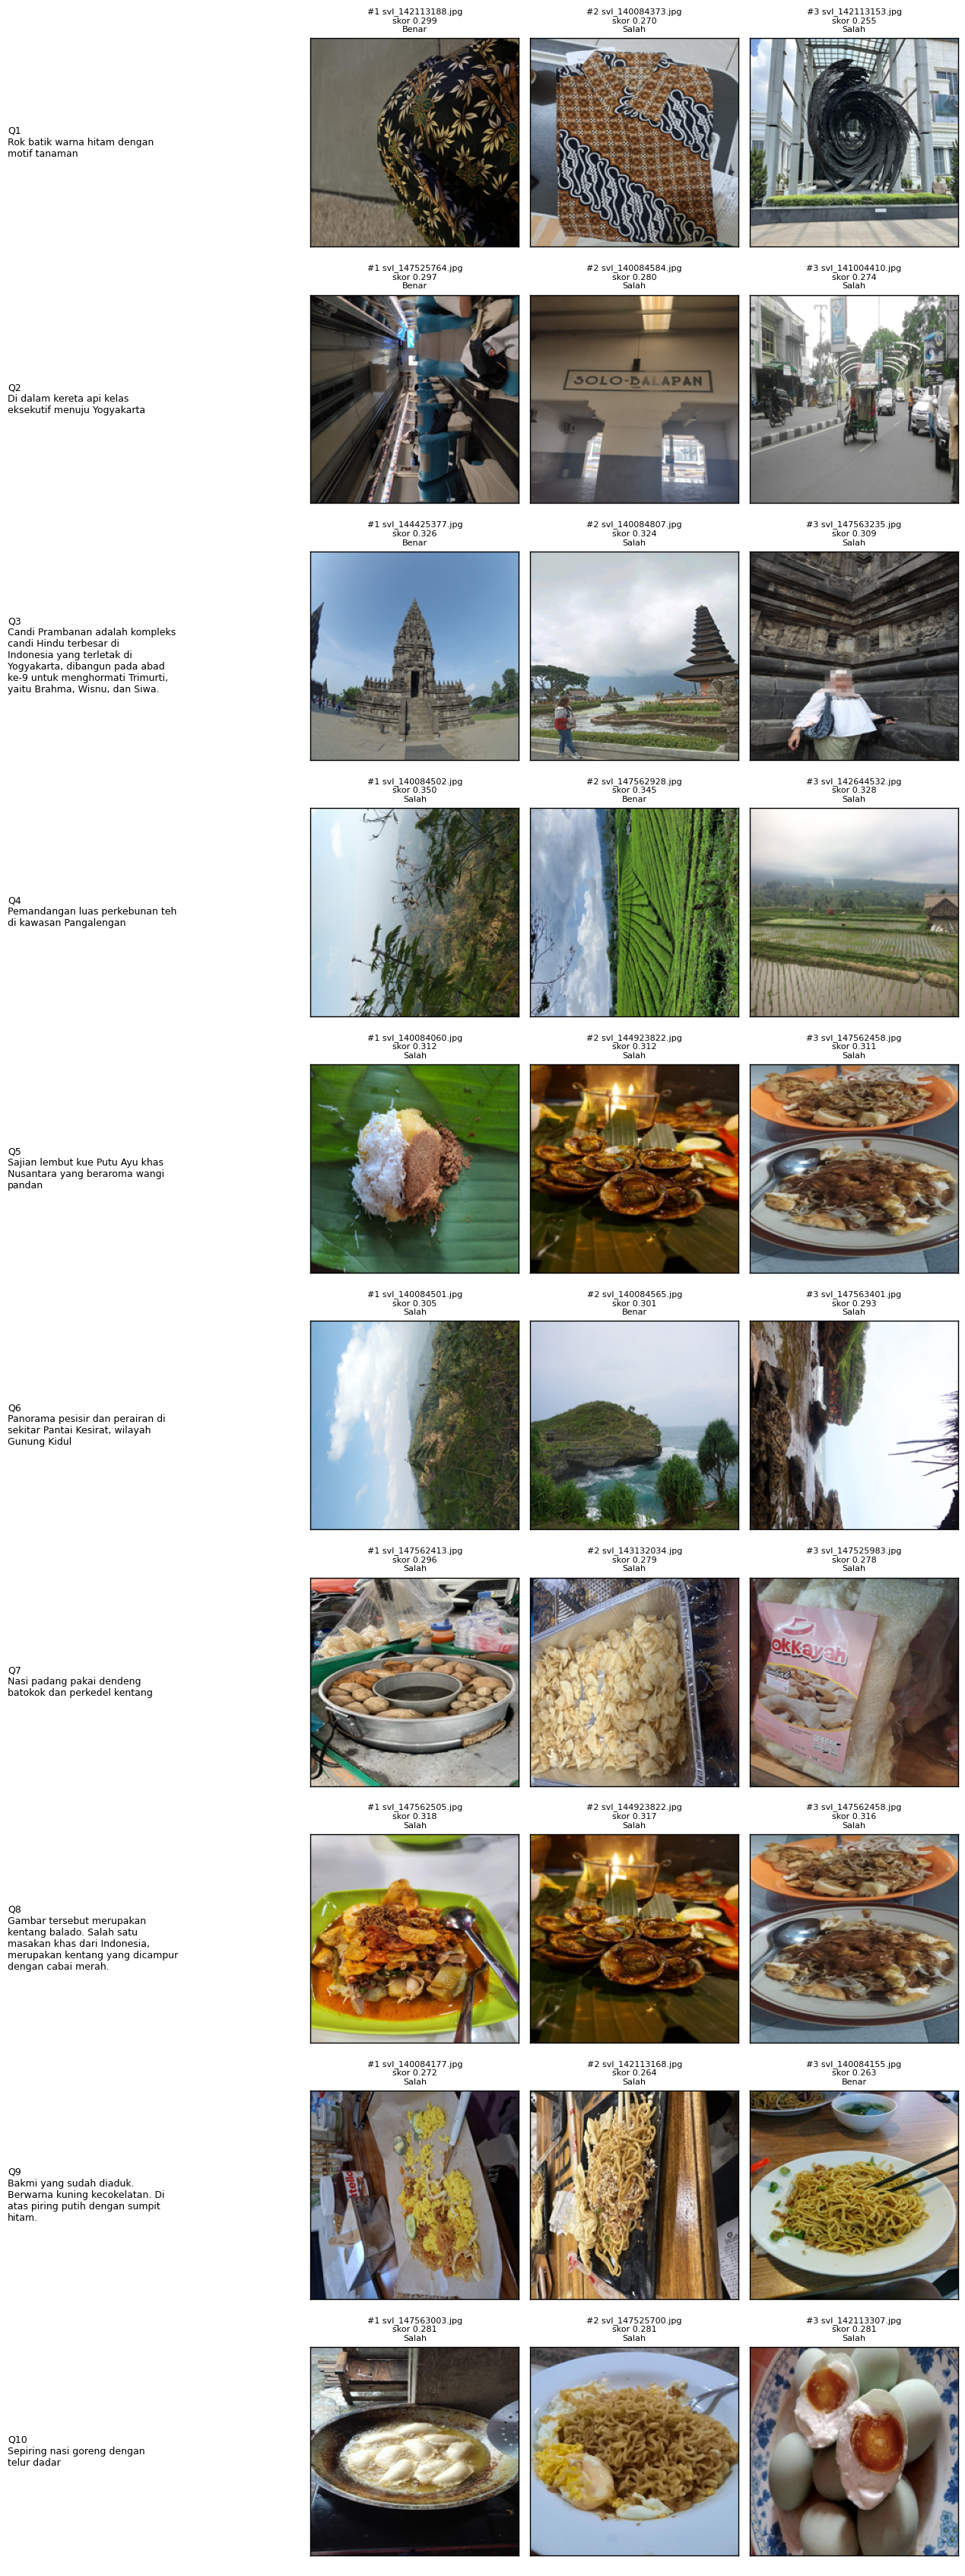

Top-1 benar: 3/10 | Top-3 ada yang benar: 6/10


In [17]:
queries_Inference = [
    "Rok batik warna hitam dengan motif tanaman",
    "Di dalam kereta api kelas eksekutif menuju Yogyakarta",
    "Candi Prambanan adalah kompleks candi Hindu terbesar di Indonesia yang terletak di Yogyakarta, dibangun pada abad ke-9 untuk menghormati Trimurti, yaitu Brahma, Wisnu, dan Siwa.",
    "Pemandangan luas perkebunan teh di kawasan Pangalengan",
    "Sajian lembut kue Putu Ayu khas Nusantara yang beraroma wangi pandan",
    "Panorama pesisir dan perairan di sekitar Pantai Kesirat, wilayah Gunung Kidul",
    "Nasi padang pakai dendeng batokok dan perkedel kentang",
    "Gambar tersebut merupakan kentang balado. Salah satu masakan khas dari Indonesia, merupakan kentang yang dicampur dengan cabai merah.",
    "Bakmi yang sudah diaduk. Berwarna kuning kecokelatan. Di atas piring putih dengan sumpit hitam.",
    "Sepiring nasi goreng dengan telur dadar"
]

Ti_Inference = txt_model.encode(queries_Inference, batch_size=64, normalize_embeddings=True)

kunci = {
    0: {"svl_142113188.jpg"},
    1: {"svl_147525764.jpg"},
    2: {"svl_144425377.jpg"},
    3: {"svl_147562928.jpg"},
    4: {"svl_142644501.jpg"},
    5: {"svl_140084565.jpg"},
    6: {"svl_140083990.jpg"},
    7: {"svl_140084024.jpg"},
    8: {"svl_140084155.jpg"},
    9: {"svl_140084730.jpg"},
}

def Top3Grid(queries, text_embeddings, image_embeddings, df, imgs, kunci=None, k=3, size=(224, 224)):
    kunci = kunci or {}
    sim = torch.tensor(text_embeddings) @ torch.tensor(image_embeddings).T
    rank = sim.argsort(dim=1, descending=True)
    n = len(queries)
    fig, axes = plt.subplots(n, k + 1, figsize=(3.2 * (k + 1), 3.4 * n), gridspec_kw={"width_ratios": [1.4] + [1] * k})
    hit1 = hit3 = dinilai = 0

    for i, q in enumerate(queries):
        axes[i, 0].axis("off")
        axes[i, 0].text(0, 0.5, f"Q{i+1}\n" + textwrap.fill(q, 32), va="center", fontsize=9)

        gt = kunci.get(i)
        benar_ke = None

        for j, idx in enumerate(rank[i, :k].tolist()):
            ax = axes[i, j + 1]
            ax.imshow(imgs[idx].resize(size))
            ax.set_xticks([]); ax.set_yticks([])
            fname = df.iloc[idx]["file"].split("/")[-1]

            if gt is None:
                label = ""
            elif fname in gt:
                label = "Benar"
                if benar_ke is None: benar_ke = j
            else:
                label = "Salah"

            for s in ax.spines.values():
                s.set_edgecolor("black"); s.set_linewidth(1)
            ax.set_title(f"#{j+1} {fname}\nskor {sim[i, idx]:.3f}\n{label}", fontsize=8, color="black")

        if gt is not None:
            dinilai += 1
            hit1 += (benar_ke == 0)
            hit3 += (benar_ke is not None)

    plt.tight_layout(); plt.show()
    if dinilai:
        print(f"Top-1 benar: {hit1}/{dinilai} | Top-3 ada yang benar: {hit3}/{dinilai}")

Top3Grid(queries_Inference, Ti_Inference, E, df_new, imgs, kunci)